Værdata hentet!
Antall målinger: 364
                       date  temperature
0 2025-01-01 00:00:00+00:00         -5.2
1 2025-01-02 00:00:00+00:00        -11.5
2 2025-01-03 00:00:00+00:00         -8.9
3 2025-01-04 00:00:00+00:00        -15.5
4 2025-01-05 00:00:00+00:00        -12.5
Værdata hentet!
Antall målinger: 364
2025-01-01T00:00:00.000Z : -5.2 °C
2025-01-02T00:00:00.000Z : -11.5 °C
2025-01-03T00:00:00.000Z : -8.9 °C
2025-01-04T00:00:00.000Z : -15.5 °C
2025-01-05T00:00:00.000Z : -12.5 °C


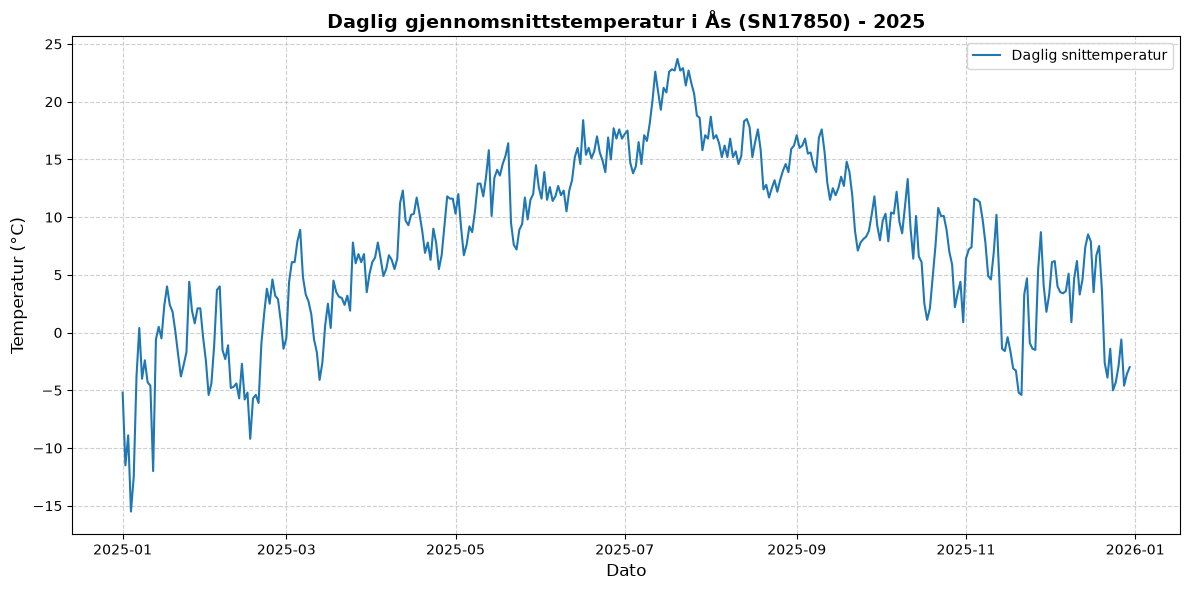


--- Oppsummeringstabell for temperatur i 2025 ---
  Statistikk  Temperatur (°C)
Gjennomsnitt         7.902747
      Median         8.400000
     Minimum       -15.500000
    Maksimum        23.700000


In [4]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import yaml

#Oppgave 1: Hent værdata fra Frost API og lag en DataFrame

#Leser Client ID fra filen
filbane = Path("client_id.txt")

with open(filbane) as f:
    client_id = f.read().strip()

#Nettadressen til Frost API
endpoint = "https://frost.met.no/observations/v0.jsonld"

#Velger værstasjon, temperatur og tidsperiode
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

#Henter værdata fra Frost
response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)
if response.status_code == 200:
    data = response.json()["data"]

    print("Værdata hentet!")
    print("Antall målinger:", len(data))

    datoer = []
    temperaturer = []

    for måling in data:
        dato = måling["referenceTime"]
        temperatur = måling["observations"][0]["value"]

        datoer.append(dato)
        temperaturer.append(temperatur)

    # Lager DataFrame
    df = pd.DataFrame({
        "date": pd.to_datetime(datoer),
        "temperature": temperaturer
    })

    print(df.head())

else:
    print("Feil:", response.status_code)
    print(response.text)

#Kontrollerer om dataene ble hentet
if response.status_code == 200:
    data = response.json()["data"]

    print("Værdata hentet!")
    print("Antall målinger:", len(data))

    # Viser de første fem målingene
    for måling in data[:5]:
        dato = måling["referenceTime"]
        temperatur = måling["observations"][0]["value"]

        print(dato, ":", temperatur, "°C")

else:
    print("Feil:", response.status_code)
    print("Feilmelding:", response.json().get("error"))



#Lag et pent plott (tid på x-aksen, temperatur på y-aksen)
plt.figure(figsize=(12, 6))

plt.plot(
    df["date"],
    df["temperature"],
    color="tab:blue",
    linewidth=1.5,
    label="Daglig snittemperatur",
)

plt.title(
    "Daglig gjennomsnittstemperatur i Ås (SN17850) - 2025",
    fontsize=14,
    fontweight="bold",
)

plt.xlabel("Dato", fontsize=12)
plt.ylabel("Temperatur (°C)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


#Lag en oppsummeringstabell med mean, median, min og max

summary_table = pd.DataFrame({
    "Statistikk": ["Gjennomsnitt", "Median", "Minimum", "Maksimum"],
    "Temperatur (°C)": [
        df["temperature"].mean(),
        df["temperature"].median(),
        df["temperature"].min(),
        df["temperature"].max(),
    ],
})

print("\n--- Oppsummeringstabell for temperatur i 2025 ---")
print(summary_table.to_string(index=False))


Oppgave 1

Vi hentet daglige gjennomsnittstemperaturer fra værstasjonen Ås (SN17850) for 2025 ved hjelp av Frost API. Grafen viser at temperaturen varierer gjennom året, med lave temperaturer om vinteren og høyere temperaturer om sommeren. Gjennomsnittstemperaturen for hele året var 7,90 °C


Nedbørsdata hentet!
Antall dataposter: 364

De første nedbørsmålingene:
        date  precipitation
0 2025-01-01            5.4
1 2025-01-01            6.6
2 2025-01-02            0.0
3 2025-01-02            1.9
4 2025-01-03            0.1


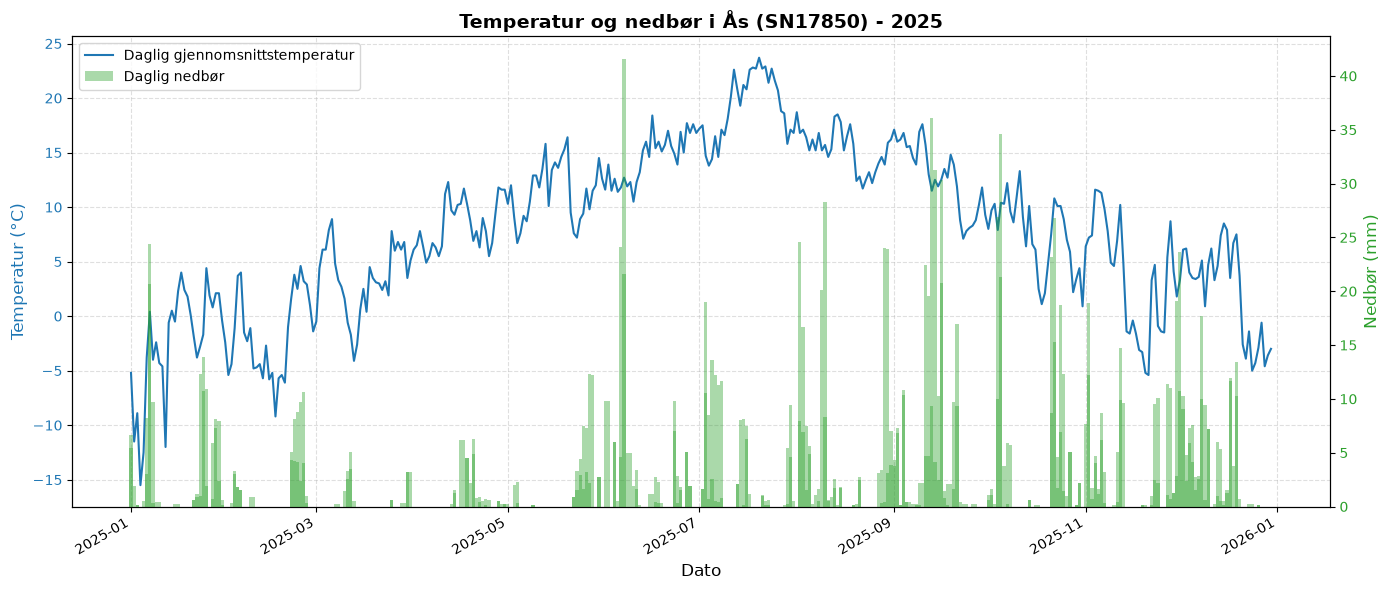

In [5]:
# Oppgave 2 Nedbør

#Henter nedbørsdata fra Frost API

parameters_precipitation = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

response_precipitation = requests.get(
    endpoint,
    params=parameters_precipitation,
    auth=(client_id, ""),
    timeout=30
)

#Kontrollerer om nedbørsdataene ble hentet

if response_precipitation.status_code == 200:

    data_precipitation = response_precipitation.json()["data"]

    print("\nNedbørsdata hentet!")
    print("Antall dataposter:", len(data_precipitation))

    #Henter dato og nedbør fra målingene

    datoer_nedbor = []
    nedbor = []

    for måling in data_precipitation:
        dato = måling["referenceTime"][:10]

        for observasjon in måling["observations"]:
            if observasjon["elementId"] == "sum(precipitation_amount P1D)":
                verdi = observasjon["value"]

                datoer_nedbor.append(dato)
                nedbor.append(verdi)

    #Lager DataFrame for nedbør

    df_precipitation = pd.DataFrame({
        "date": pd.to_datetime(datoer_nedbor),
        "precipitation": nedbor
    })

    print("\nDe første nedbørsmålingene:")
    print(df_precipitation.head())

    #Kombinerer temperatur og nedbør

    df_temperature = df.copy()
    df_temperature["date"] = pd.to_datetime(
        df_temperature["date"]
    ).dt.tz_localize(None).dt.normalize()

    df_combined = pd.merge(
        df_temperature,
        df_precipitation,
        on="date",
        how="outer"
    )

    df_combined = df_combined.sort_values("date")

    #Lager graf med to y-akser

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Blå linje for temperatur
    ax1.plot(
        df_combined["date"],
        df_combined["temperature"],
        color="tab:blue",
        linewidth=1.5,
        label="Daglig gjennomsnittstemperatur"
    )

    ax1.set_xlabel("Dato", fontsize=12)
    ax1.set_ylabel(
        "Temperatur (°C)",
        color="tab:blue",
        fontsize=12
    )

    ax1.tick_params(axis="y", labelcolor="tab:blue")
    ax1.grid(True, linestyle="--", alpha=0.4)

    #Grønne stolper for nedbør

    ax2 = ax1.twinx()

    ax2.bar(
        df_combined["date"],
        df_combined["precipitation"],
        color="tab:green",
        alpha=0.4,
        width=1.0,
        label="Daglig nedbør"
    )

    ax2.set_ylabel(
        "Nedbør (mm)",
        color="tab:green",
        fontsize=12
    )

    ax2.tick_params(axis="y", labelcolor="tab:green")
    ax2.set_ylim(bottom=0)

    #Formaterer grafen

    plt.title(
        "Temperatur og nedbør i Ås (SN17850) - 2025",
        fontsize=14,
        fontweight="bold"
    )

    linjer1, navn1 = ax1.get_legend_handles_labels()
    linjer2, navn2 = ax2.get_legend_handles_labels()

    ax1.legend(
        linjer1 + linjer2,
        navn1 + navn2,
        loc="upper left"
    )

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

else:
    print("Feil ved henting av nedbørsdata:")
    print("Statuskode:", response_precipitation.status_code)
    print(response_precipitation.text)


Oppgave 2

Vi hentet daglige nedbørsdata for 2025 og kombinerte dem med temperaturdataene fra oppgave 1. Vi brukte en blå linje for temperatur og grønne stolper for nedbør. Grafen viser at nedbøren varierer mye fra dag til dag, og at enkelte dager har betydelig mer nedbør enn andre. Det er ingen tydelig direkte sammenheng mellom temperatur og nedbør i grafen.


Historiske temperaturdata hentet!
Antall målinger fra 1925: 364

De første temperaturmålingene fra 1925:
                       date  temperature
0 1925-01-01 00:00:00+00:00          1.3
1 1925-01-02 00:00:00+00:00          4.1
2 1925-01-03 00:00:00+00:00          2.1
3 1925-01-04 00:00:00+00:00          0.1
4 1925-01-05 00:00:00+00:00         -2.2


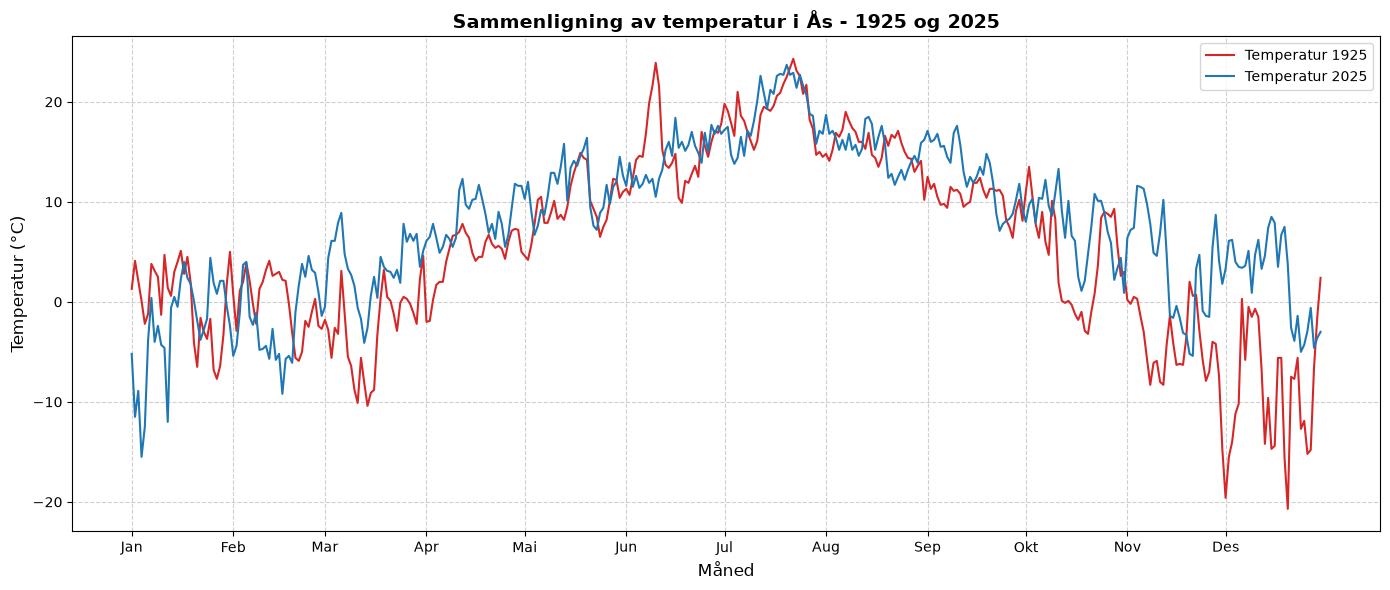


--- Temperaturstatistikk for 1925 og 2025 ---
  Statistikk  1925 (°C)  2025 (°C)
Gjennomsnitt       5.31        7.9
      Median       5.30        8.4
     Minimum     -20.70      -15.5
    Maksimum      24.30       23.7

Forskjell i gjennomsnittstemperatur: 2.59 °C


In [6]:
#Oppgave 3 Historisk tempratur data
#Henter temperaturdata fra 1925

parameters_1925 = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1925-12-31"
}

response_1925 = requests.get(
    endpoint,
    params=parameters_1925,
    auth=(client_id, ""),
    timeout=30
)

#Kontrollerer om dataene ble hentet

if response_1925.status_code == 200:

    data_1925 = response_1925.json()["data"]

    print("\nHistoriske temperaturdata hentet!")
    print("Antall målinger fra 1925:", len(data_1925))

    #Henter dato og temperatur fra 1925

    datoer_1925 = []
    temperaturer_1925 = []

    for måling in data_1925:
        dato = måling["referenceTime"]
        
        for observasjon in måling["observations"]:
            if observasjon["elementId"] == "mean(air_temperature P1D)":
                temperatur = observasjon["value"]

                datoer_1925.append(dato)
                temperaturer_1925.append(temperatur)

    #Lager DataFrame for 1925

    df_1925 = pd.DataFrame({
        "date": pd.to_datetime(datoer_1925),
        "temperature": temperaturer_1925
    })

    df_1925 = df_1925.sort_values("date")

    print("\nDe første temperaturmålingene fra 1925:")
    print(df_1925.head())

    #Forbereder dataene for sammenligning

    df_2025 = df.copy()
    df_2025["date"] = pd.to_datetime(df_2025["date"])

    # Bruker dagnummer i året på x-aksen
    df_1925["day_of_year"] = df_1925["date"].dt.dayofyear
    df_2025["day_of_year"] = df_2025["date"].dt.dayofyear

    #Lager graf for 1925 og 2025

    plt.figure(figsize=(14, 6))

    # Rød linje for 1925
    plt.plot(
        df_1925["day_of_year"],
        df_1925["temperature"],
        color="tab:red",
        linewidth=1.5,
        label="Temperatur 1925"
    )

    # Blå linje for 2025
    plt.plot(
        df_2025["day_of_year"],
        df_2025["temperature"],
        color="tab:blue",
        linewidth=1.5,
        label="Temperatur 2025"
    )

    #Formaterer grafen

    plt.title(
        "Sammenligning av temperatur i Ås - 1925 og 2025",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Måned", fontsize=12)
    plt.ylabel("Temperatur (°C)", fontsize=12)

    # Plasserer månedene på x-aksen
    maaneder = pd.date_range(
        "2025-01-01",
        "2025-12-01",
        freq="MS"
    )

    plt.xticks(
        maaneder.dayofyear,
        ["Jan", "Feb", "Mar", "Apr", "Mai", "Jun",
         "Jul", "Aug", "Sep", "Okt", "Nov", "Des"]
    )

    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

    #Lager oppsummeringstabell

    summary_1925_2025 = pd.DataFrame({
        "Statistikk": [
            "Gjennomsnitt",
            "Median",
            "Minimum",
            "Maksimum"
        ],
        "1925 (°C)": [
            df_1925["temperature"].mean(),
            df_1925["temperature"].median(),
            df_1925["temperature"].min(),
            df_1925["temperature"].max()
        ],
        "2025 (°C)": [
            df_2025["temperature"].mean(),
            df_2025["temperature"].median(),
            df_2025["temperature"].min(),
            df_2025["temperature"].max()
        ]
    })

    # Avrunder til to desimaler
    summary_1925_2025 = summary_1925_2025.round(2)

    print("\n--- Temperaturstatistikk for 1925 og 2025 ---")
    print(summary_1925_2025.to_string(index=False))

    #Beregner forskjellen i gjennomsnittstemperatur

    forskjell = (
        df_2025["temperature"].mean()
        - df_1925["temperature"].mean()
    )

    print(
        f"\nForskjell i gjennomsnittstemperatur: "
        f"{forskjell:.2f} °C"
    )

else:
    print("\nKunne ikke hente temperaturdata fra 1925.")
    print("Statuskode:", response_1925.status_code)
    print("Feilmelding:", response_1925.text)



Oppgave 3

Vi sammenlignet temperaturene i Ås fra 1925 og 2025. Gjennomsnittstemperaturen var 5,31 °C i 1925 og 7,90 °C i 2025, en forskjell på 2,59 °C. Resultatene viser at 2025 var varmere i gjennomsnitt enn 1925. Samtidig er to enkeltår ikke nok til å konkludere om langsiktige klimaendringer.

In [10]:
#Oppgave 4 Hetebølger

#Funksjon som teller hetebølger
def count_heatwaves(station_id, year, station_name):

    #Henter maksimumstemperatur fra Frost API
    parameters_heatwave = {
        "sources": station_id,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year}-12-31"
    }

    response_heatwave = requests.get(
        endpoint,
        params=parameters_heatwave,
        auth=(client_id, ""),
        timeout=30
    )

    #Kontrollerer om dataene ble hentet
    if response_heatwave.status_code != 200:
        print("Feil ved henting av temperaturdata:")
        print("Statuskode:", response_heatwave.status_code)
        print(response_heatwave.text)
        return None

    data_heatwave = response_heatwave.json()["data"]

    #Lager DataFrame med dato og maksimumstemperatur
    measurements = []

    for measurement in data_heatwave:
        date = measurement["referenceTime"][:10]

        for observation in measurement["observations"]:
            if observation["elementId"] == "max(air_temperature P1D)":
                measurements.append({
                    "date": date,
                    "max_temperature": observation["value"]
                })

    df_heatwave = pd.DataFrame(measurements)

    if df_heatwave.empty:
        print("Ingen temperaturmålinger funnet.")
        return None

    df_heatwave["date"] = pd.to_datetime(
        df_heatwave["date"]
    )

    df_heatwave = df_heatwave.sort_values("date")

    # Bruker én maksimumstemperatur per dato
    df_heatwave = df_heatwave.drop_duplicates(
        subset="date"
    )

    #Finner hetebølger
    heatwaves = []

    start_date = None
    previous_date = None
    consecutive_days = 0

    for _, row in df_heatwave.iterrows():

        date = row["date"]
        temperature = row["max_temperature"]

        # Sjekker om temperaturen er minst 27 grader
        if pd.notna(temperature) and temperature >= 27:

            # Fortsetter en sammenhengende varmeperiode
            if (
                consecutive_days > 0
                and previous_date is not None
                and (date - previous_date).days == 1
            ):
                consecutive_days += 1

            else:
                # Lagrer forrige periode hvis den var lang nok
                if consecutive_days >= 5:
                    heatwaves.append({
                        "start": start_date,
                        "end": previous_date,
                        "days": consecutive_days
                    })

                # Starter en ny varmeperiode
                consecutive_days = 1
                start_date = date

        else:
            # Avslutter perioden hvis temperaturen
            # er under 27 grader eller mangler
            if consecutive_days >= 5:
                heatwaves.append({
                    "start": start_date,
                    "end": previous_date,
                    "days": consecutive_days
                })

            consecutive_days = 0
            start_date = None

        previous_date = date

    #Kontrollerer siste varmeperiode
    if consecutive_days >= 5:
        heatwaves.append({
            "start": start_date,
            "end": previous_date,
            "days": consecutive_days
        })

    #Teller og skriver ut hetebølgene
    number_of_heatwaves = len(heatwaves)

    print(f"\n--- Hetebølger i {station_name}, {year} ---")
    print("Antall hetebølger:", number_of_heatwaves)

    #Lager datoliste i lærerens YAML-format
    dates = []

    for heatwave in heatwaves:
        start = heatwave["start"].strftime("%Y-%m-%d")
        end = heatwave["end"].strftime("%Y-%m-%d")

        period = f"{start} - {end}"
        dates.append(period)

        print(
            f"Fra {start} til {end} "
            f"({heatwave['days']} dager)"
        )

    #Lager oppsummering lik lærerens eksempel
    summary = {
        "dates": dates,
        "station_id": station_id,
        "station_name": station_name,
        "year": year
    }

    #Lagrer resultatene i en YAML-fil
  
    #Lagrer resultatene i en YAML-fil
    filename = (
        Path.cwd()
        / f"heatwaves_{station_id}_{year}.yml"
    )

    with open(filename, "w", encoding="utf-8") as file:
        yaml.safe_dump(
            summary,
            file,
            allow_unicode=True,
            sort_keys=False,
            default_flow_style=False
        )

    print("\nResultatene er lagret i:", filename)

    return number_of_heatwaves


#Kjører funksjonen for Ås i 2025
count_heatwaves("SN17850", 2025, "Ås")





--- Hetebølger i Ås, 2025 ---
Antall hetebølger: 1
Fra 2025-07-16 til 2025-07-20 (5 dager)

Resultatene er lagret i: /Users/30abdsar/Desktop/H2026/INF201 Videregående programmering/heatwaves_SN17850_2025.yml


1

Oppgave 4

Vi laget en funksjon som finner hetebølger ved å undersøke om maksimumstemperaturen er minst 27 °C i fem eller flere sammenhengende dager. Funksjonen henter temperaturdata fra Frost API, teller hetebølgene og lagrer resultatene i en YAML-fil. I vår beregning fant vi én hetebølge i Ås i 2025, fra 16. til 20. juli. Funksjonen kan også brukes for andre år og værstasjoner.


--- 7-dagers glidende gjennomsnitt ---
      date  temperature  moving_average
2025-01-01         -5.2             NaN
2025-01-02        -11.5             NaN
2025-01-03         -8.9             NaN
2025-01-04        -15.5             NaN
2025-01-05        -12.5             NaN
2025-01-06         -3.8             NaN
2025-01-07          0.4       -8.142857
2025-01-08         -4.0       -7.971429
2025-01-09         -2.4       -6.671429
2025-01-10         -4.3       -6.014286


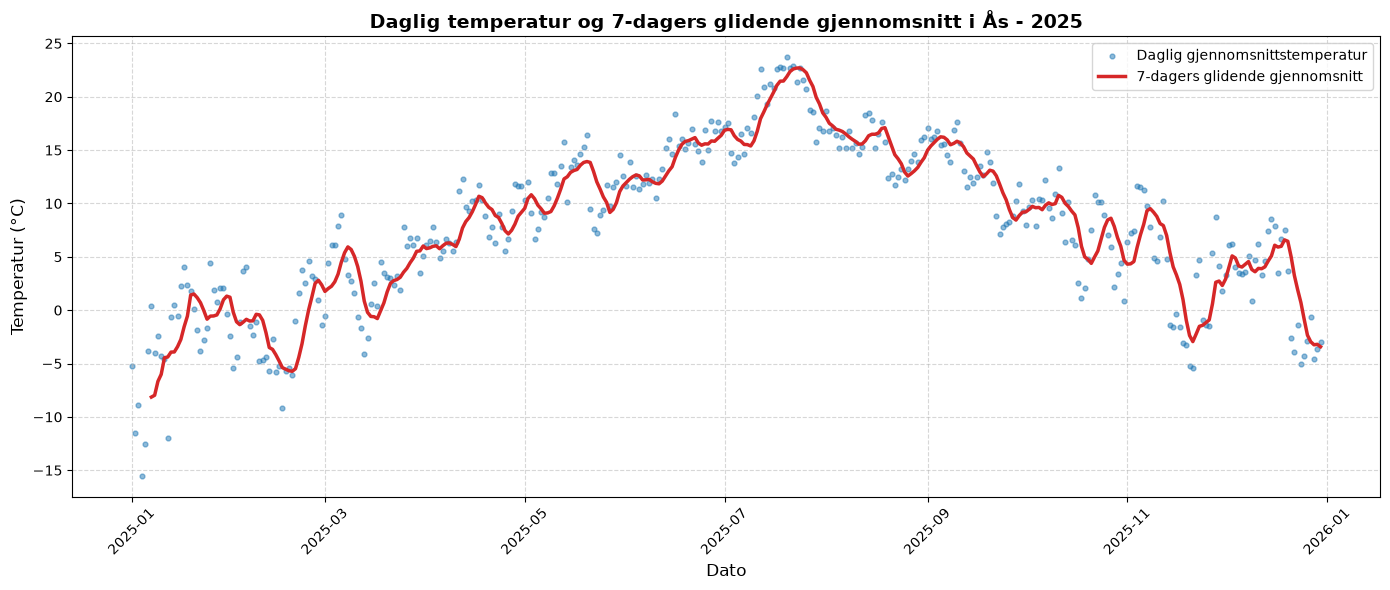

In [11]:
#Oppgave 5 Glidendene gjennomsnitttempratur

# Lager en funksjon som beregner
# 7-dagers glidende gjennomsnitt

def moving_average_temperature(data, window=7):

    # Lager en kopi av DataFrame
    df_average = data.copy()

    # Gjør datoene om til datetime
    df_average["date"] = pd.to_datetime(
        df_average["date"]
    ).dt.tz_localize(None).dt.normalize()

    # Sorterer dataene etter dato
    df_average = df_average.sort_values("date")

    # Bruker dato som indeks og fyller inn
    # eventuelle manglende kalenderdager
    df_average = df_average.set_index("date")
    df_average = df_average.asfreq("D")

    # Beregner 7-dagers glidende gjennomsnitt
    df_average["moving_average"] = (
        df_average["temperature"]
        .rolling(window=window, min_periods=window)
        .mean()
    )

    # Gjør dato tilbake til en vanlig kolonne
    df_average = df_average.reset_index()

    return df_average


#Bruker funksjonen på temperaturdata fra 2025

df_moving = moving_average_temperature(df, window=7)

# 3. Skriver ut de første 10 radene
print("\n--- 7-dagers glidende gjennomsnitt ---")
print(df_moving.head(10).to_string(index=False))


#Lager grafen
plt.figure(figsize=(14, 6))

# Blå punkter viser daglig gjennomsnittstemperatur
plt.scatter(
    df_moving["date"],
    df_moving["temperature"],
    color="tab:blue",
    s=12,
    alpha=0.5,
    label="Daglig gjennomsnittstemperatur"
)

# Rød linje viser 7-dagers glidende gjennomsnitt
plt.plot(
    df_moving["date"],
    df_moving["moving_average"],
    color="tab:red",
    linewidth=2.5,
    label="7-dagers glidende gjennomsnitt"
)

#Formaterer grafen
plt.title(
    "Daglig temperatur og 7-dagers glidende "
    "gjennomsnitt i Ås - 2025",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Dato", fontsize=12)
plt.ylabel("Temperatur (°C)", fontsize=12)

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

#Viser grafen
plt.show()



Oppgave 5
 
Vi laget en funksjon som beregner 7-dagers glidende gjennomsnitt av temperaturen i 2025. Grafen viser daglige temperaturer som blå punkter og det glidende gjennomsnittet som en rød linje. Den røde linjen er jevnere fordi kortvarige temperatursvingninger blir redusert. Dette gjør det lettere å se den generelle temperaturutviklingen gjennom året.